# CNN 바운딩박스 - 고양이

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
import os

In [2]:
import random

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

np.set_printoptions(precision=4, linewidth=200, suppress=True)

# 데이터 준비

In [3]:
!gdown https://drive.google.com/uc?id=12st-LKpy5fZ2RCMtC4ZPcVwQl62NCnVt

Downloading...
From: https://drive.google.com/uc?id=12st-LKpy5fZ2RCMtC4ZPcVwQl62NCnVt
To: /content/cat_bb.zip
100% 993k/993k [00:00<00:00, 154MB/s]


In [4]:
!unzip cat_bb.zip

Archive:  cat_bb.zip
   creating: cat_bb/
   creating: cat_bb/example/
  inflating: cat_bb/example/cat-104_jpg.rf.2a24b28217199b0deb97f08d04a4554d.jpg  
  inflating: cat_bb/example/cat-105_jpg.rf.c2a86a1bbbd2692274d6d6084512e920.jpg  
  inflating: cat_bb/example/cat-106_jpg.rf.322ad5d4a7a55ea19fdf75154bf492e9.jpg  
  inflating: cat_bb/example/cat-107_jpg.rf.45eb2698455834f5d5e10f32ab5d9a40.jpg  
  inflating: cat_bb/example/cat-111_jpg.rf.3a2689de6862347f22c8e43b13b07102.jpg  
  inflating: cat_bb/example/cat-115_jpg.rf.7c3bd4387e39dd58f3fff6d730232036.jpg  
   creating: cat_bb/test/
  inflating: cat_bb/test/cat-110_jpg.rf.919d96206faca75068ac5595928f4005.jpg  
  inflating: cat_bb/test/cat-110_jpg.rf.919d96206faca75068ac5595928f4005.xml  
  inflating: cat_bb/test/cat-123_jpg.rf.9a0878d7d6e110b302293109a66b43bf.jpg  
  inflating: cat_bb/test/cat-123_jpg.rf.9a0878d7d6e110b302293109a66b43bf.xml  
  inflating: cat_bb/test/cat-143_jpg.rf.61045dbe235b78c5fdf8d2267b0bea85.jpg  
  inflating: cat

In [5]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 22.1 MB/s eta 0:00:00


In [6]:
import cv2
import os
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [11]:
import yaml

# Path to the dataset YAML file
yaml_path = '/content/cat_data.yaml'

# Read the existing YAML content
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# Update the paths to point to the correct directories
# The images are directly in cat_bb/train and cat_bb/test, and labels are in cat_bb/train/labels and cat_bb/test/labels
# Ultralytics expects the 'train' and 'val' keys to point to the image directories
# and will automatically look for a 'labels' subdirectory if it exists.
data['train'] = '/content/cat_bb/train'
data['val'] = '/content/cat_bb/test'

# Write the modified content back to the YAML file
with open(yaml_path, 'w') as f:
    yaml.dump(data, f, default_flow_style=False)

print(f"Updated {yaml_path} with correct training and validation paths.")

model = YOLO('yolov8n.pt')

model.train(data=yaml_path, epochs=50, imgsz=640, device=0)

Updated /content/cat_data.yaml with correct training and validation paths.
Ultralytics 8.3.246 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cat_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train4, nbs=64, nms=False, opset=None, optimize=False, opti

/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:836: RuntimeWarning: Mean of empty slice.
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


       2/50      2.26G          0      114.1          0          0        640: 100% ━━━━━━━━━━━━ 6/6 13.2it/s 0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 21.3it/s 0.0s
                   all         11          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, cannot compute metrics without labels


/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:836: RuntimeWarning: Mean of empty slice.
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.26G          0      107.4          0          0        640: 100% ━━━━━━━━━━━━ 6/6 13.7it/s 0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 29.8it/s 0.0s
                   all         11          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, cannot compute metrics without labels


/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:836: RuntimeWarning: Mean of empty slice.
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


... (94 outputs left out)


50 epochs completed in 0.010 hours.
Optimizer stripped from /content/runs/detect/train4/weights/last.pt, 6.2MB
Optimizer stripped from /content/runs/detect/train4/weights/best.pt, 6.2MB

Validating /content/runs/detect/train4/weights/best.pt...
Ultralytics 8.3.246 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 32.5it/s 0.0s


/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:655: RuntimeWarning: Mean of empty slice.
  ax.plot(px, py.mean(1), linewidth=3, color="blue", label=f"all classes {ap[:, 0].mean():.3f} mAP@0.5")
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:700: RuntimeWarning: Mean of empty slice.
  y = smooth(py.mean(0), 0.1)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:700: RuntimeWarning: Mean of empty slice.
  y = smooth(py.mean(0), 0.1)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.12/dist-packages/ultraly

                   all         11          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, cannot compute metrics without labels
Speed: 0.1ms preprocess, 0.8ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/train4


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([], dtype=int64)
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e4326c1a600>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

먼저, XML 레이블 파일을 YOLO 형식으로 변환합니다.

In [10]:
import os
import xml.etree.ElementTree as ET

def convert_xml_to_yolo(xml_file_path, image_width, image_height, output_dir):
    tree = ET.parse(xml_file_path)
    root = tree.getroot()

    # The dataset contains only 'cat_face', so class_id is always 0
    class_id = 0

    yolo_labels = []
    for obj in root.findall('object'):
        bbox = obj.find('bndbox')
        xmin = float(bbox.find('xmin').text)
        ymin = float(bbox.find('ymin').text)
        xmax = float(bbox.find('xmax').text)
        ymax = float(bbox.find('ymax').text)

        # Convert to YOLO format (normalized x_center, y_center, width, height)
        x_center = (xmin + xmax) / 2 / image_width
        y_center = (ymin + ymax) / 2 / image_height
        width = (xmax - xmin) / image_width
        height = (ymax - ymin) / image_height

        yolo_labels.append(f"{class_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")

    # Get base name for the output .txt file
    base_name = os.path.basename(xml_file_path).replace('.xml', '.txt')
    output_path = os.path.join(output_dir, base_name)

    with open(output_path, 'w') as f:
        for line in yolo_labels:
            f.write(line + '\n')

def process_data_split(data_dir):
    image_dir = data_dir
    label_output_dir = os.path.join(data_dir, 'labels')
    os.makedirs(label_output_dir, exist_ok=True)

    for filename in os.listdir(image_dir):
        if filename.endswith('.jpg'):
            image_path = os.path.join(image_dir, filename)
            xml_file_path = image_path.replace('.jpg', '.xml')

            if os.path.exists(xml_file_path):
                # Assume a fixed image size or read from image if needed
                # For simplicity, using a common size (e.g., 640x640) or reading from image
                # If images are not all 640x640, this needs to be adjusted
                # For now, let's assume they are all effectively resized to 640x640 during training
                # However, the original image dimensions are needed for correct normalization
                # Let's read the image to get its original dimensions
                import cv2
                img = cv2.imread(image_path)
                if img is None: # handle potential error for empty image files
                    print(f"Warning: Could not read image {image_path}. Skipping.")
                    continue
                h, w, _ = img.shape

                convert_xml_to_yolo(xml_file_path, w, h, label_output_dir)

# Process train and test directories
base_data_path = '/content/cat_bb'
process_data_split(os.path.join(base_data_path, 'train'))
process_data_split(os.path.join(base_data_path, 'test'))

print("XML label files converted to YOLO format.")

XML label files converted to YOLO format.


In [12]:
import os

def check_structure(base_path):
    for root, dirs, files in os.walk(base_path):
        level = root.replace(base_path, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/ - (파일 {len(files)}개)")
        if len(files) > 0 and (root.endswith('labels')):
            with open(os.path.join(root, files[0]), 'r') as f:
                print(f"{indent}   [라벨 내용 예시]: {f.readline().strip()}")

check_structure('/content/cat_bb')

cat_bb/ - (파일 2개)
    train/ - (파일 182개)
        labels/ - (파일 91개)
           [라벨 내용 예시]: 0 0.263393 0.386161 0.482143 0.584821
    .ipynb_checkpoints/ - (파일 0개)
    example/ - (파일 6개)
    test/ - (파일 22개)
        labels/ - (파일 11개)
           [라벨 내용 예시]: 0 0.546875 0.350446 0.433036 0.611607


In [13]:
import os
import shutil

def organize_yolo_dataset(base_path):
    for split in ['train', 'test']:
        split_path = os.path.join(base_path, split)
        img_dir = os.path.join(split_path, 'images')

        # 1. images 폴더 생성
        os.makedirs(img_dir, exist_ok=True)

        # 2. 이미지 파일(.jpg, .png 등)을 images 폴더로 이동
        for file in os.listdir(split_path):
            if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                shutil.move(os.path.join(split_path, file), os.path.join(img_dir, file))

        # 3. 잘못된 캐시 파일 삭제 (매우 중요!)
        cache_file = os.path.join(base_path, f"{split}.cache")
        if os.path.exists(cache_file):
            os.remove(cache_file)
            print(f"Removed: {cache_file}")

    print("✅ 폴더 구조 정리가 완료되었습니다!")

organize_yolo_dataset('/content/cat_bb')

Removed: /content/cat_bb/train.cache
Removed: /content/cat_bb/test.cache
✅ 폴더 구조 정리가 완료되었습니다!


In [14]:
import yaml

data = {
    'path': '/content/cat_bb',
    'train': 'train/images', # 이미지 폴더 지정
    'val': 'test/images',   # 테스트용을 검증용으로 활용
    'names': {0: 'cat_face'}
}

with open('/content/cat_data.yaml', 'w') as f:
    yaml.dump(data, f)

In [16]:
from ultralytics import YOLO

# 모델 로드
model = YOLO('yolo11n.pt') # 최신 v11 나노 모델 사용 권장 (파일 이름 수정: 'yolov11n.pt' -> 'yolo11n.pt')

# 학습 실행
results = model.train(
    data='/content/cat_data.yaml',
    epochs=50,
    imgsz=640,
    batch=32, # A100이므로 32~64도 넉넉합니다
    device=0
)

Ultralytics 8.3.246 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cat_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train5, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, p


image 1/11 /content/cat_bb/test/images/cat-110_jpg.rf.919d96206faca75068ac5595928f4005.jpg: 640x640 1 cat_face, 10.7ms
image 2/11 /content/cat_bb/test/images/cat-123_jpg.rf.9a0878d7d6e110b302293109a66b43bf.jpg: 640x640 1 cat_face, 9.7ms
image 3/11 /content/cat_bb/test/images/cat-143_jpg.rf.61045dbe235b78c5fdf8d2267b0bea85.jpg: 640x640 1 cat_face, 10.0ms
image 4/11 /content/cat_bb/test/images/cat-144_jpg.rf.50b4b01d0df37d977b1341837708aa1d.jpg: 640x640 1 cat_face, 10.3ms
image 5/11 /content/cat_bb/test/images/cat-188_jpg.rf.4bb417309154766edeac39c9c9d083f7.jpg: 640x640 1 cat_face, 9.3ms
image 6/11 /content/cat_bb/test/images/cat-207_jpg.rf.9634274bd68e49fcd575d53e83e72cae.jpg: 640x640 2 cat_faces, 9.5ms
image 7/11 /content/cat_bb/test/images/cat-243_jpg.rf.1da8871668b6d7bbe4a3d5aa11fd046e.jpg: 640x640 1 cat_face, 9.5ms
image 8/11 /content/cat_bb/test/images/cat-249_jpg.rf.eba7bf7e8fe79642e84fdc3abc72e6f2.jpg: 640x640 1 cat_face, 9.5ms
image 9/11 /content/cat_bb/test/images/cat-255_jpg.

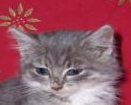


✅ 모든 작업 완료! /content/cat_faces_cropped 폴더에서 고양이 얼굴들을 확인하세요.


In [17]:
import cv2
import os
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

# 1. 학습된 최적의 모델 불러오기 (가장 최근 학습 폴더인 train5 확인)
model = YOLO('/content/runs/detect/train5/weights/best.pt')

# 2. 경로 설정
test_images_path = '/content/cat_bb/test/images'
save_path = '/content/cat_faces_cropped'
os.makedirs(save_path, exist_ok=True)

# 3. 테스트 데이터 추론 및 얼굴 자르기
results = model(test_images_path)

print("\n--- 이미지 크롭 작업 시작 ---")
for i, r in enumerate(results):
    img = r.orig_img  # 원본 이미지 불러오기

    # 감지된 얼굴(박스)들에 대해 반복
    for j, box in enumerate(r.boxes.xyxy):
        # 좌표값 추출 [xmin, ymin, xmax, ymax]
        x1, y1, x2, y2 = map(int, box)

        # 이미지 슬라이싱으로 얼굴 영역만 Crop
        face_img = img[y1:y2, x1:x2]

        # 결과 저장 (파일명: 사진순서_얼굴순서.jpg)
        save_name = f"cropped_cat_{i}_{j}.jpg"
        cv2.imwrite(os.path.join(save_path, save_name), face_img)

        # 첫 번째 사진만 화면에 한번 보여주기 (확인용)
        if i == 0:
            print(f"샘플 확인: {save_name}")
            cv2_imshow(face_img)

print(f"\n✅ 모든 작업 완료! {save_path} 폴더에서 고양이 얼굴들을 확인하세요.")


image 1/1 /content/cat_bb/test/images/cat-144_jpg.rf.50b4b01d0df37d977b1341837708aa1d.jpg: 640x640 1 cat_face, 9.6ms
Speed: 4.6ms preprocess, 9.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-188_jpg.rf.4bb417309154766edeac39c9c9d083f7.jpg: 640x640 1 cat_face, 9.1ms
Speed: 2.1ms preprocess, 9.1ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-207_jpg.rf.9634274bd68e49fcd575d53e83e72cae.jpg: 640x640 2 cat_faces, 9.0ms
Speed: 2.0ms preprocess, 9.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-273_jpg.rf.af452afbb9bb8767d534653a290090c2.jpg: 640x640 (no detections), 8.8ms
Speed: 2.0ms preprocess, 8.8ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-110_jpg.rf.919d96206faca75068ac5595928f4005.jpg: 640x640 1 cat_face, 9.9ms
Speed: 2.3ms preproc

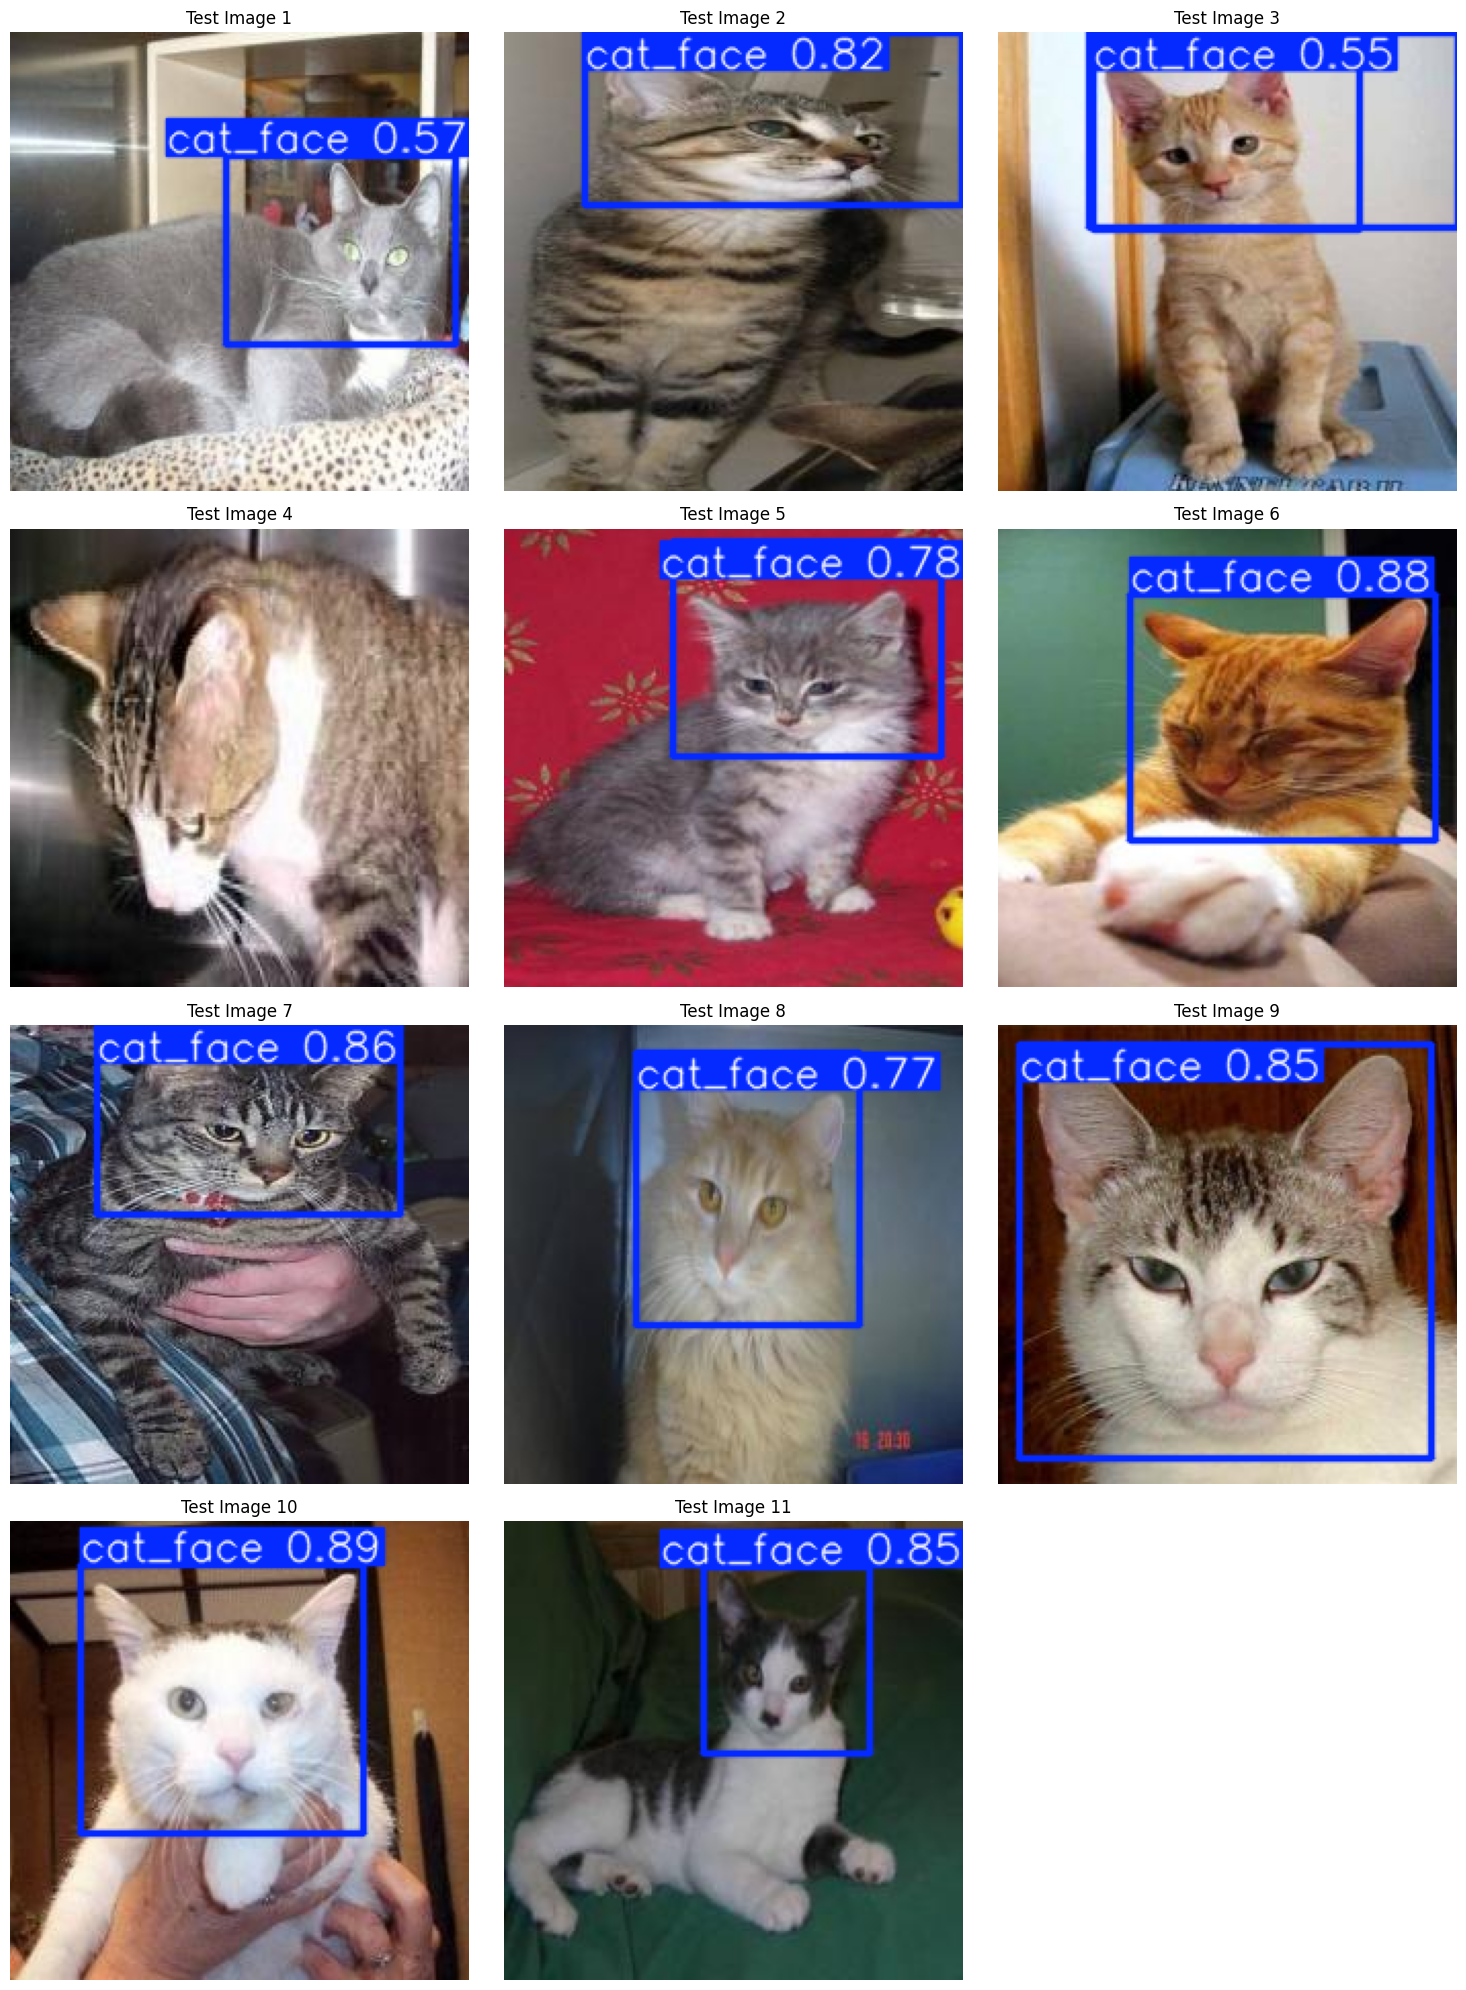

In [18]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
import os

# 1. 학습된 모델 로드
model = YOLO('/content/runs/detect/train5/weights/best.pt')

# 2. 테스트 이미지 경로
test_img_dir = '/content/cat_bb/test/images'
test_img_list = [os.path.join(test_img_dir, f) for f in os.listdir(test_img_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]

# 3. 시각화 설정 (여러 장을 한 번에 보기 위해 subplot 사용)
num_images = len(test_img_list)
cols = 3  # 한 줄에 보여줄 사진 수
rows = (num_images // cols) + (1 if num_images % cols != 0 else 0)

plt.figure(figsize=(15, 5 * rows))

for i, img_path in enumerate(test_img_list):
    # 모델 추론
    results = model(img_path)

    # YOLO의 내장 plot 함수로 박스가 그려진 이미지 생성 (BGR 형태)
    # labels=True, boxes=True 옵션으로 정보 표시 제어 가능
    annotated_frame = results[0].plot()

    # Matplotlib은 RGB를 사용하므로 BGR -> RGB 변환
    annotated_frame_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

    # 서브플롯에 출력
    plt.subplot(rows, cols, i + 1)
    plt.imshow(annotated_frame_rgb)
    plt.title(f"Test Image {i+1}")
    plt.axis('off') # 격자 숨기기

plt.tight_layout()
plt.show()

In [19]:
import torch

# 1. 학습된 모델에서 PyTorch 모델 추출
pytorch_model = model.model

# 2. 레이어 구조 출력
print(pytorch_model)

# 3. 특정 레이어만 확인 (예: 첫 번째 Conv 레이어)
first_layer = pytorch_model.model[0]
print(f"\n첫 번째 레이어 구성:\n{first_layer}")

DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (act): SiLU(inplace=True)
    )
    (2): C3k2(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1))
        (act): SiLU(inplace=True)
      )
      (m): ModuleList(
        (0): Bottleneck(
          (cv1): Conv(
            (conv): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (act): SiLU(inplace=True)
          )
          (cv2): Conv(
            (conv): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (act): SiLU(inplace=True)
          )
        )
      )
    )
    (3): Conv(
      (conv): Conv2d(64,

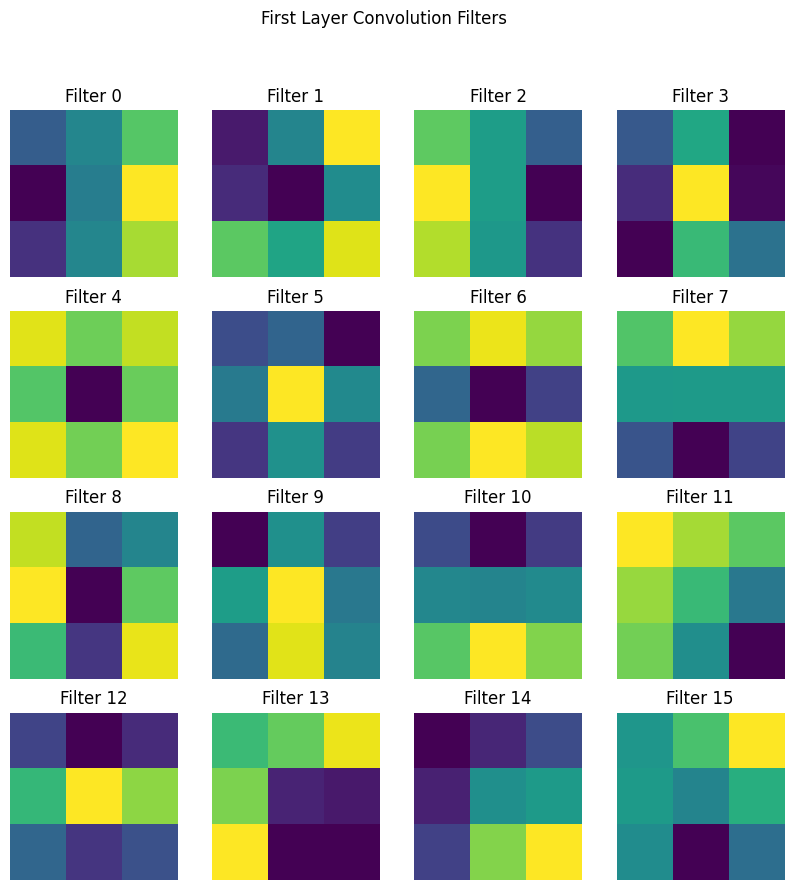

In [20]:
import matplotlib.pyplot as plt

# 첫 번째 컨볼루션 레이어의 가중치(Weight) 가져오기
# 구조: [output_channels, input_channels, kernel_h, kernel_w]
weights = pytorch_model.model[0].conv.weight.data.cpu()

# 시각화 (첫 16개 필터)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    if i < weights.shape[0]:
        # 가중치를 0~1 사이로 정규화하여 출력
        f = weights[i, 0, :, :] # 첫 번째 입력 채널(R)에 대응하는 필터
        ax.imshow(f, cmap='viridis')
        ax.set_title(f"Filter {i}")
    ax.axis('off')

plt.suptitle("First Layer Convolution Filters")
plt.show()

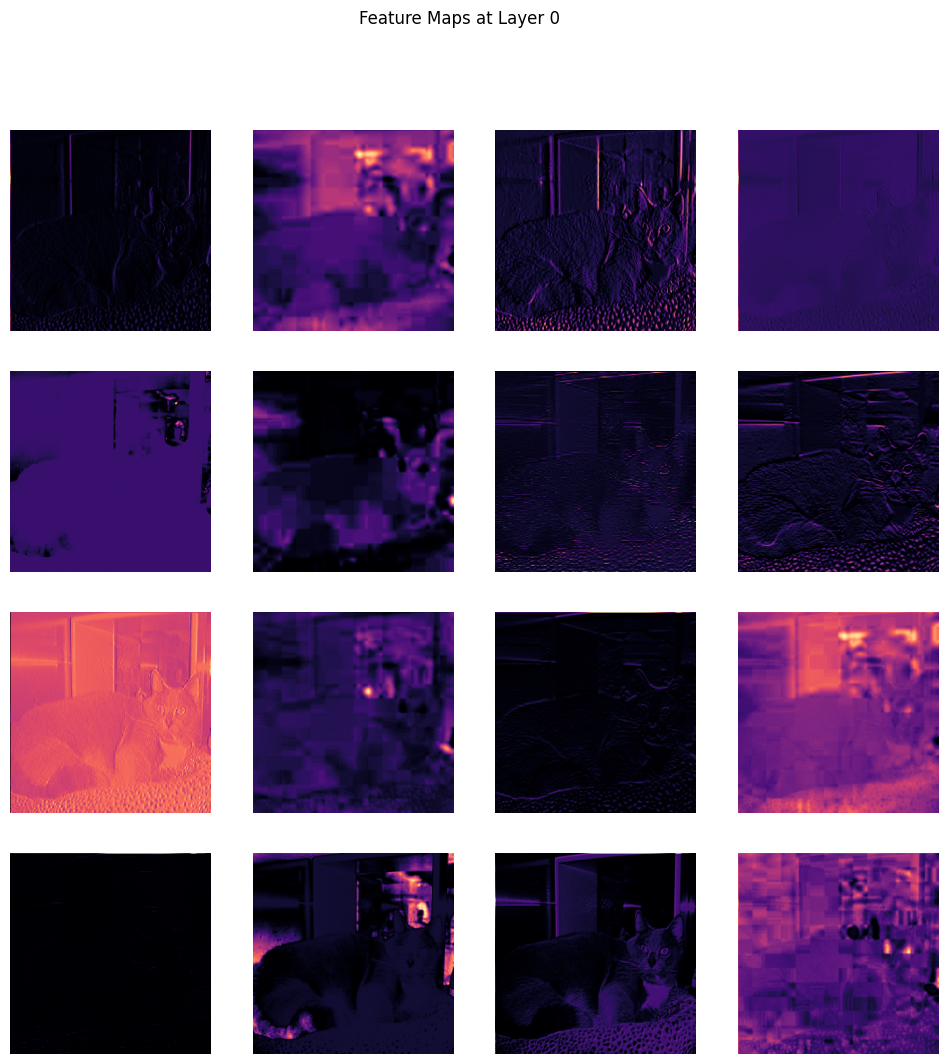

In [21]:
def visualize_feature_maps(model, img_path, layer_num=0):
    # 이미지 전처리
    img = cv2.imread(img_path)
    img = cv2.resize(img, (640, 640))
    img_tensor = torch.from_numpy(img).permute(2, 0, 1).float().unsqueeze(0).to(0) / 255.0

    # 특정 레이어까지의 출력 계산
    model.eval()
    with torch.no_grad():
        # YOLO의 내부 레이어 리스트에 순차적으로 입력 전달
        x = img_tensor
        for i in range(layer_num + 1):
            x = model.model[i](x)

    # 피처 맵 시化 (첫 16개 채널)
    feature_maps = x[0].cpu().numpy()
    fig, axes = plt.subplots(4, 4, figsize=(12, 12))
    for i, ax in enumerate(axes.flat):
        ax.imshow(feature_maps[i], cmap='magma')
        ax.axis('off')
    plt.suptitle(f"Feature Maps at Layer {layer_num}")
    plt.show()

# 첫 번째 레이어(0번)의 결과 확인
visualize_feature_maps(pytorch_model, test_img_list[0], layer_num=0)

--- 신뢰도 점수 수집 시작 ---

image 1/1 /content/cat_bb/test/images/cat-144_jpg.rf.50b4b01d0df37d977b1341837708aa1d.jpg: 640x640 1 cat_face, 9.9ms
Speed: 2.2ms preprocess, 9.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-188_jpg.rf.4bb417309154766edeac39c9c9d083f7.jpg: 640x640 1 cat_face, 9.9ms
Speed: 2.3ms preprocess, 9.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-207_jpg.rf.9634274bd68e49fcd575d53e83e72cae.jpg: 640x640 2 cat_faces, 9.4ms
Speed: 2.1ms preprocess, 9.4ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-273_jpg.rf.af452afbb9bb8767d534653a290090c2.jpg: 640x640 (no detections), 9.1ms
Speed: 2.0ms preprocess, 9.1ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/cat_bb/test/images/cat-110_jpg.rf.919d96206faca75068ac5595928f4005.jpg: 640x640 1 cat_face, 9.0ms

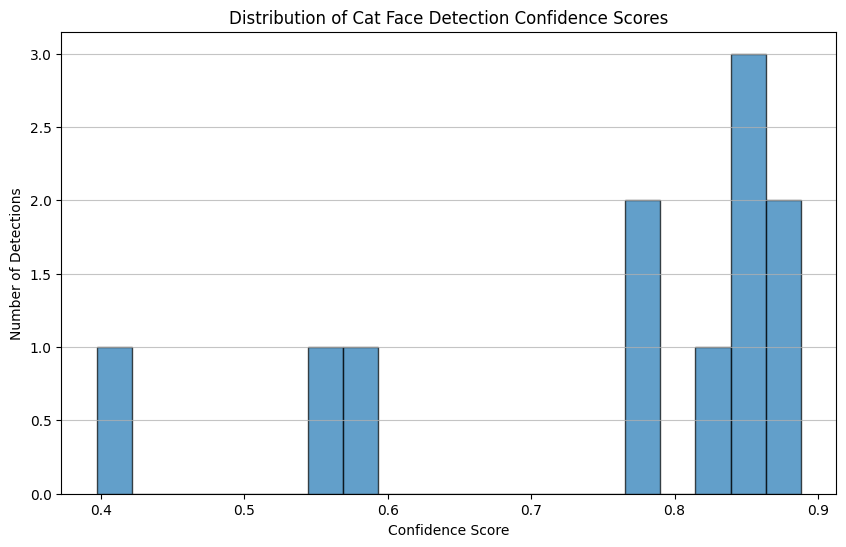


--- 신뢰도 점수 통계 ---
최소 신뢰도: 0.3970
최대 신뢰도: 0.8882
평균 신뢰도: 0.7477


In [23]:
import matplotlib.pyplot as plt
import os
from ultralytics import YOLO

# 1. 학습된 모델 로드 (이전 셀에서 로드된 모델 사용)
model = YOLO('/content/runs/detect/train5/weights/best.pt')

# 2. 테스트 이미지 경로
test_img_dir = '/content/cat_bb/test/images'
test_img_list = [os.path.join(test_img_dir, f) for f in os.listdir(test_img_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]

# 3. 모든 감지된 고양이 얼굴의 신뢰도 점수를 저장할 리스트
all_confidence_scores = []

print("--- 신뢰도 점수 수집 시작 ---")
for img_path in test_img_list:
    # 모델 추론
    results = model(img_path)

    # 각 이미지의 감지 결과에서 바운딩 박스와 신뢰도 점수 추출
    for r in results:
        for box in r.boxes:
            # box.conf는 감지된 객체의 신뢰도 점수입니다.
            all_confidence_scores.append(box.conf.item()) # .item()을 사용하여 텐서를 Python 숫자로 변환

print(f"✅ 총 {len(all_confidence_scores)}개의 고양이 얼굴 신뢰도 점수 수집 완료.")

# 4. 신뢰도 점수 분포 시각화 (히스토그램)
plt.figure(figsize=(10, 6))
plt.hist(all_confidence_scores, bins=20, edgecolor='black', alpha=0.7)
plt.title('Distribution of Cat Face Detection Confidence Scores')
plt.xlabel('Confidence Score')
plt.ylabel('Number of Detections')
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\n--- 신뢰도 점수 통계 ---")
if all_confidence_scores:
    print(f"최소 신뢰도: {min(all_confidence_scores):.4f}")
    print(f"최대 신뢰도: {max(all_confidence_scores):.4f}")
    print(f"평균 신뢰도: {sum(all_confidence_scores) / len(all_confidence_scores):.4f}")
else:
    print("수집된 신뢰도 점수가 없습니다.")